In [1]:
import sys
sys.path.insert(0, "..")

from utils.modelling import *
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score

In [2]:
Xtrain, ytrain, Xval, yval, Xtest, ytest = load_train_val_test('../data/processed/dataset.csv')

In [3]:
missing = pd.DataFrame({
    "missing_%": Xtrain[NUMERIC].isna().mean() * 100,
    "median": Xtrain[NUMERIC].median(),
    "mean": Xtrain[NUMERIC].mean(),
})
missing.round(3)

,missing_%,median,mean
HEIGHT,33.447,50.000,943.219
SPEED,57.242,140.000,144.306
DISTANCE,44.840,0.000,2.017
BodyMass,58.418,0.051,0.265
log_ImpactEnergy,87.007,5.200,5.375
AC_MASS,0.627,4.000,3.581
NUM_ENGS,0.769,2.000,1.972


In [4]:
weights = make_class_weights(ytrain)

def make_imputation_preprocessor(strategy="median", indicators=True):
    return make_preprocessor(model="A").set_params(
        num__simpleimputer__strategy=strategy,
        num__simpleimputer__add_indicator=indicators,
        ord__simpleimputer__add_indicator=indicators,
    )

classifiers = {
    "Logistic regression": lambda: LogisticRegression(class_weight=weights(0.5), max_iter=1000),
    "Decision tree": lambda: DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, class_weight=weights(0.25), random_state=67),
}
settings = [("median", True), ("mean", True), ("median", False), ("mean", False)]

imputation_results = []
for name, classifier in classifiers.items():
    for strategy, indicators in settings:
        model = make_pipeline(make_imputation_preprocessor(strategy, indicators), classifier())
        scores = cross_val_score(model, Xtrain, ytrain, cv=5, scoring="f1_macro", n_jobs=-1)
        model.fit(Xtrain, ytrain)
        val_f1 = f1_score(yval, model.predict(Xval), average="macro")
        imputation_results.append({"model": name, "imputation": strategy, "missing_indicators": indicators, "cv_f1_mean": scores.mean(), "cv_f1_std": scores.std(), "val_f1_macro": val_f1})
        print(imputation_results[-1])

imputation_results = pd.DataFrame(imputation_results)
imputation_results.to_csv("../results/imputation.csv", index=False)
imputation_results

{'model': 'Logistic regression', 'imputation': 'median', 'missing_indicators': True, 'cv_f1_mean': np.float64(0.48400054660005837), 'cv_f1_std': np.float64(0.008462619377905772), 'val_f1_macro': 0.47265309583102955}


{'model': 'Logistic regression', 'imputation': 'mean', 'missing_indicators': True, 'cv_f1_mean': np.float64(0.4837898720067537), 'cv_f1_std': np.float64(0.008372186756937522), 'val_f1_macro': 0.47367759295449824}


{'model': 'Logistic regression', 'imputation': 'median', 'missing_indicators': False, 'cv_f1_mean': np.float64(0.48504456745281244), 'cv_f1_std': np.float64(0.0034003762822108555), 'val_f1_macro': 0.4687831033004724}


{'model': 'Logistic regression', 'imputation': 'mean', 'missing_indicators': False, 'cv_f1_mean': np.float64(0.48468608019712917), 'cv_f1_std': np.float64(0.004880504785095608), 'val_f1_macro': 0.4697031824599698}


{'model': 'Decision tree', 'imputation': 'median', 'missing_indicators': True, 'cv_f1_mean': np.float64(0.4746177477307727), 'cv_f1_std': np.float64(0.017285657877179117), 'val_f1_macro': 0.4536853190122602}


{'model': 'Decision tree', 'imputation': 'mean', 'missing_indicators': True, 'cv_f1_mean': np.float64(0.47571800780745505), 'cv_f1_std': np.float64(0.009798530937567246), 'val_f1_macro': 0.45162889058968303}


{'model': 'Decision tree', 'imputation': 'median', 'missing_indicators': False, 'cv_f1_mean': np.float64(0.4730160520275527), 'cv_f1_std': np.float64(0.016045064431324817), 'val_f1_macro': 0.44287683696568064}


{'model': 'Decision tree', 'imputation': 'mean', 'missing_indicators': False, 'cv_f1_mean': np.float64(0.4749740369858719), 'cv_f1_std': np.float64(0.009363111308211611), 'val_f1_macro': 0.4489119430043597}


,model,imputation,missing_indicators,cv_f1_mean,cv_f1_std,val_f1_macro
0,Logistic regression,median,True,0.484001,0.008463,0.472653
1,Logistic regression,mean,True,0.483790,0.008372,0.473678
2,Logistic regression,median,False,0.485045,0.003400,0.468783
3,Logistic regression,mean,False,0.484686,0.004881,0.469703
4,Decision tree,median,True,0.474618,0.017286,0.453685
5,Decision tree,mean,True,0.475718,0.009799,0.451629
6,Decision tree,median,False,0.473016,0.016045,0.442877
7,Decision tree,mean,False,0.474974,0.009363,0.448912


## plots

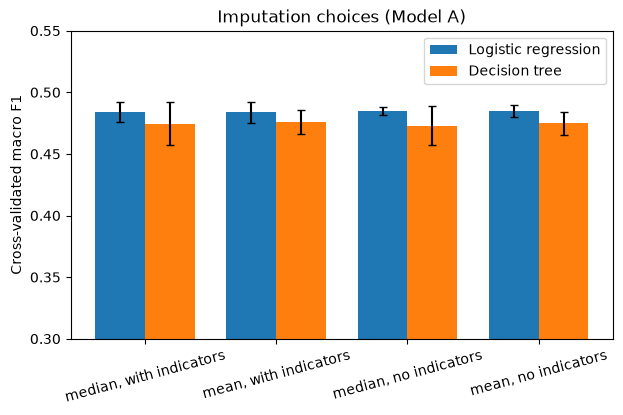

In [5]:
import matplotlib.pyplot as plt

labels = [f"{s}, {'with' if i else 'no'} indicators" for s, i in settings]
x = np.arange(len(settings))
fig, ax = plt.subplots(figsize=(7, 4))
for k, (name, group) in enumerate(imputation_results.groupby("model", sort=False)):
    ax.bar(x + (k - 0.5) * 0.38, group["cv_f1_mean"], width=0.38, yerr=group["cv_f1_std"], capsize=3, label=name)
ax.set_xticks(x, labels, rotation=15)
ax.set_ylim(0.3, 0.55)
ax.set_ylabel("Cross-validated macro F1")
ax.set_title("Imputation choices (Model A)")
ax.legend()
fig.savefig("../plots/imputation.png", dpi=200, bbox_inches="tight")